In [3]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('monthly-milk-production-pounds-p.csv')
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


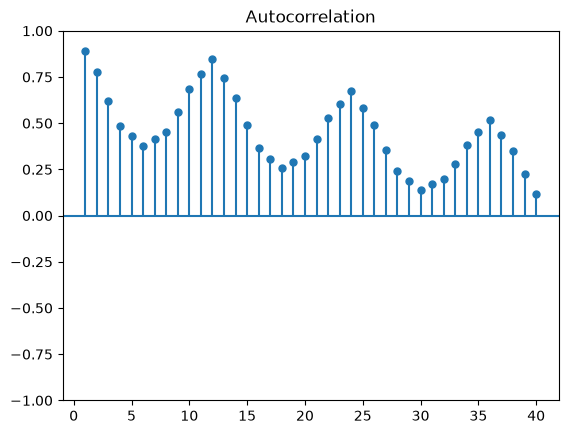

In [5]:
plot_acf(df['Milk'] , lags = 40, alpha = None, zero = False)
plt.show()

In [6]:
result = adfuller(df['Milk'], maxlag = 10)
print('P-value = ', result[1])

if result[1] < 0.05: 
    print(f'Time series is stationary')
else:
    print(f'Time series is not stationary')
    

P-value =  0.6443832606930111
Time series is not stationary


In [8]:
diff_1= df['Milk'].diff().dropna()
result = adfuller(diff_1 , maxlag = 10)
print('P-value = ', result[1])

if result[1] < 0.05: 
    print(f'Time series is stationary')  # reject null hypothesis
else:
    print(f'Time series is not stationary') # accept null hypothesis

P-value =  0.0
Time series is stationary


In [10]:
y = df['Milk']
y_train = y[:-12]
y_test = y[-12:]

# ARIMA

Coefficient : ar.L1       -0.303601
ma.L1        0.255714
ma.L2        0.140010
ma.L3       -0.426401
ma.L4       -0.639144
sigma2    1333.305542
dtype: float64
Test RMSE: 56.694 
Coefficient : ar.L1       -0.087896
ar.L2        0.272233
ma.L1        0.120660
sigma2    1882.401208
dtype: float64
Test RMSE: 72.863 


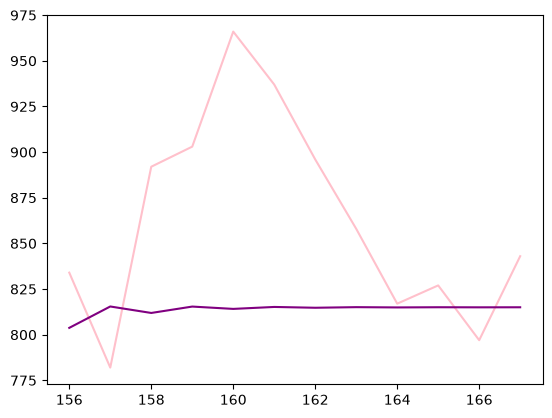

In [28]:
# order =   p           d            q
# AR Lags order , Order of diff , Moving Average

model = ARIMA(y_train , order=(1,1,4))
model_fit = model.fit()

print('Coefficient : %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train), end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, predictions)

print('Test RMSE: %.3f '% error)




model = ARIMA(y_train , order=(2,1,1))
model_fit = model.fit()

print('Coefficient : %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train), end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, predictions)

print('Test RMSE: %.3f '% error)

y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

In [23]:
from pmdarima.arima import auto_arima

In [24]:
model = auto_arima(y_train , trace=True, error_action = 'ignore', suppress_warnings = True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.685, Time=0.59 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.10 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.31 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.24 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.59 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.322, Time=0.81 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.68 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.05 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.41 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1561.833, Time=1.10 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.92 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.03 s

In [26]:
forecast = model.predict(n_periods = len(y_test))
forecast = pd.DataFrame(forecast , index = y_test.index ,columns = ['Prediction'])
rms = root_mean_squared_error(y_test , forecast)
rms

57.87840101837533

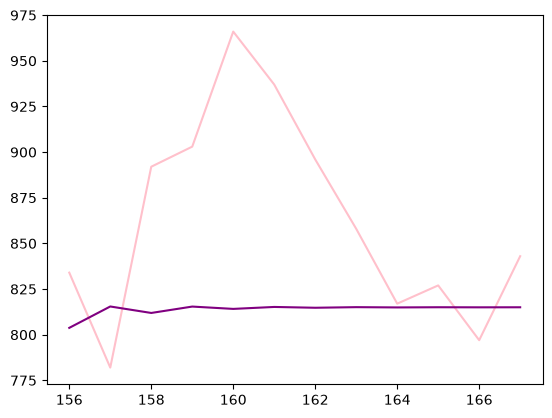

In [27]:
y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

# SARIMA

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.685, Time=0.67 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.15 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.44 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.31 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.67 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.322, Time=0.84 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.52 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.77 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.92 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1561.833, Time=1.01 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.89 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.09 s

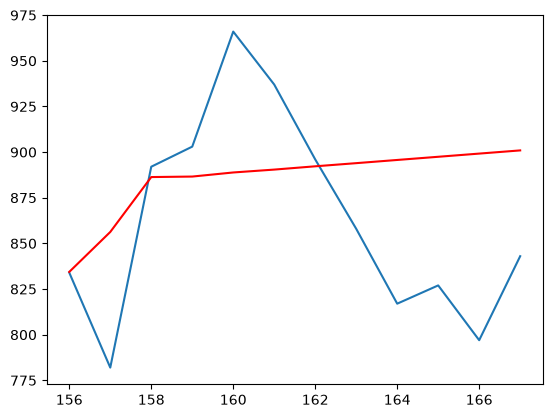

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.96 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.04 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.46 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.58 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.03 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=1.79 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.43 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=2.66 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.26 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=5.69 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=1.23 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.26 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.61 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=1.74 sec
 ARIMA(1,0,2)(1,1,0)[12] int

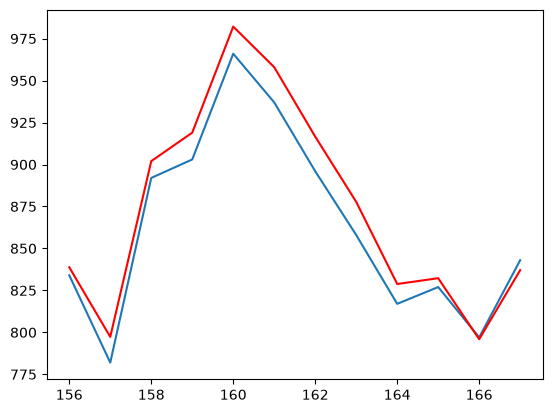

In [30]:
model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True)

model.bse

forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('Test RMSE: %.3f' % rmse)

plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()

model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)

forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('Test RMSE: %.3f' % rmse)

plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()